# Build Halo

ma 1e-22
Using NFW profile without soliton core
M_tot: 9.07e+08 M_sun
Done.
seed 0
Enclosed mass in rfit_max = 10^8.897689567919628
Iteration #1
Solving for eigenmodes...
Sampling grid for eigenvalue problem includes 62499 bins, out to r_max = 200.0 kpc
(returning only eigenmodes with energies below circular orbits at r_fit = 80.0 kpc)
n_max = 20
l = 0; n_max = 20
l = 1; n_max = 19
l = 2; n_max = 19
l = 3; n_max = 18
l = 4; n_max = 17
l = 5; n_max = 17
l = 6; n_max = 16
l = 7; n_max = 15
l = 8; n_max = 15
l = 9; n_max = 14
l = 10; n_max = 13
l = 11; n_max = 12
l = 12; n_max = 12
l = 13; n_max = 11
l = 14; n_max = 10
l = 15; n_max = 9
l = 16; n_max = 8
l = 17; n_max = 8
l = 18; n_max = 7
l = 19; n_max = 6
l = 20; n_max = 5
l = 21; n_max = 4
l = 22; n_max = 3
l = 23; n_max = 2
l = 24; n_max = 1
l = 25; n_max = 1
n_max = 20; l_max = 26; distinct nl modes = 282; total modes = 5050
Solving for amplitudes...
32 unique amplitudes
   0    2.103038
 100   -2.325426
 200   -2.327648
 300   -2.32

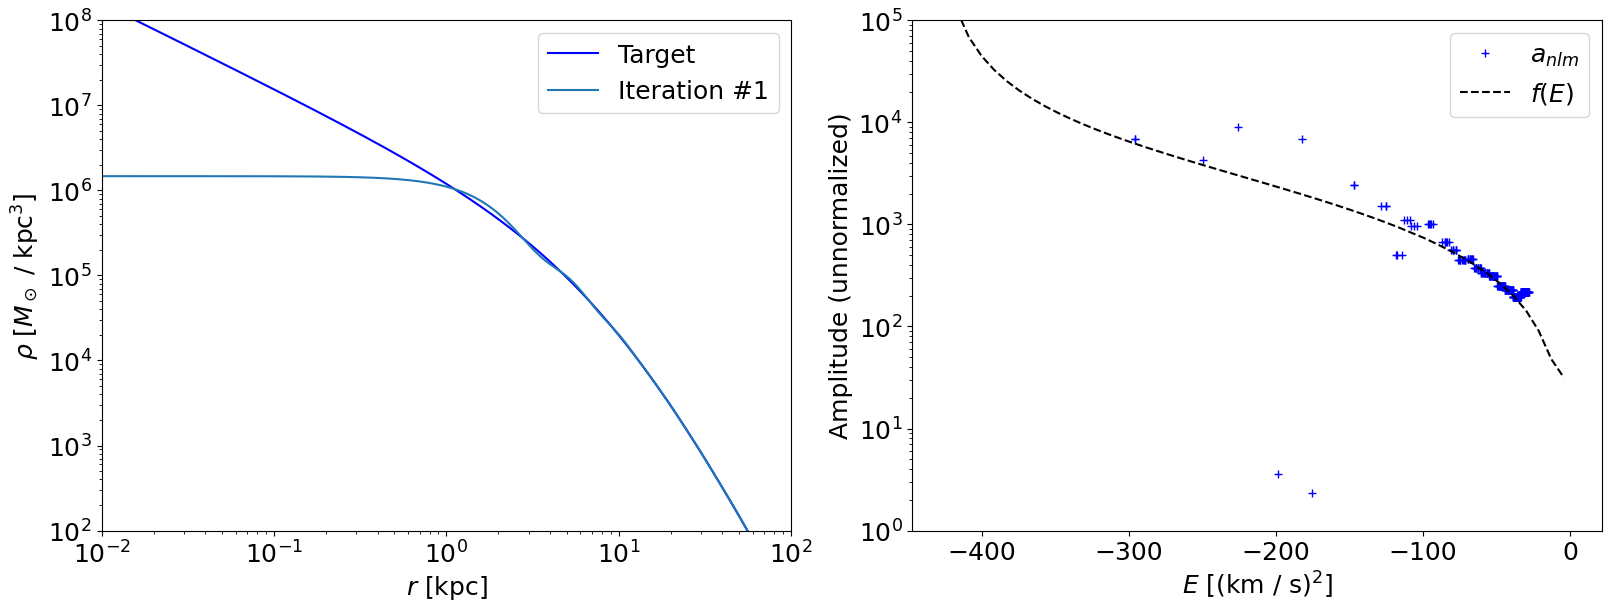

Completed!
Seed 0: total modes=5050, active modes=5050


100%|██████████| 110/110 [15:17<00:00,  8.34s/it]


Done.


Seed 0 potentials: 100%|██████████| 110/110 [00:08<00:00, 13.58it/s]


In [ ]:
import healpy as hp
import fdmtools
import os

# import ctypes
import numpy as np
import matplotlib.pyplot as plt
import scipy.interpolate as scinterp


from tqdm import tqdm
from multiprocessing import Pool, cpu_count
import warnings
# gsl_path="/XYFS01/pxy80/lib"
# os.environ["LD_LIBRARY_PATH"] = gsl_path + ':' + os.environ.get('LD_LIBRARY_PATH','')
# ctypes.cdll.LoadLibrary(gsl_path + '/libintlc.so.5')
# ctypes.cdll.LoadLibrary(gsl_path + '/libirng.so')
# ctypes.cdll.LoadLibrary(gsl_path + '/libsvml.so')
# ctypes.cdll.LoadLibrary(gsl_path + '/libimf.so')
# ctypes.cdll.LoadLibrary(gsl_path + '/libgsl.so.27')
# ctypes.cdll.LoadLibrary(gsl_path + '/libgslcblas.so.0') 

Ggal = 4.30091727e-6
hbar = 6.582119569509067e-16    # Reduced Planck constant in eV * s
c_constant = 2.99792458e5       # Speed of light in km/s

# Conversions:
km_to_kpc = 3.240779289444365e-17       # Conversion from km to kpc
km_s_to_kpc_gyr = 1.022712165045695     # Conversion from km/s to kpc/Gyr

# Cosmology
Om = 0.2865                     # Omega matter
rho_crit = 133.36363195167573   # Critical background density (solMass / kpc^3)
rho_m = rho_crit * Om           # Background matter density at present
overdensity = 347.0             # Overdensity for spherical collapse
rho_vir = overdensity * rho_m   # Average density within the virial radius

# =============================
# Runtime configuration
# =============================
have_soliton = True              # Whether to include the soliton core in the initial profile (if False, use pure NFW)
m_as = [1.0e-22]                 # FDM particle mass in eV / c^2
Nmaxes = [None]                  # Maximum principle quantum number for mode truncation (None means no truncation)
seeds = np.arange(20)            # Realizations

# Halo / profile setup
r_setup_res = 512
a = 10.
M = 1e9
R_max = 200.
R_fit = 80.

# Time setup
t_step = 0.1                    # Evolution time step in Gyr
t_stop = 11.                    # Total evolution time in Gyr
ramp_up = 10                    # Number of steps to ramp up the fluctuations
t_array = np.arange(start=0., stop=t_stop, step=t_step)
timesteps = len(t_array)

# Orbit IC setup (used in cell 2)
R_scales = {'5pc': 0.005, '10pc': 0.01, '20pc': 0.02}
nparticle = 10000
t_to_Myr = 977.79222168
warnings.filterwarnings('ignore')


for Nmax in Nmaxes:
    for m_a in m_as:
        fdm = fdmtools.FDMTools(m_a)                          # Initialize FDM tools
    
        print(f'ma {m_a}')
        h_over_m = hbar / (m_a / c_constant**2) * km_to_kpc     # Scaled unit (h_bar / m_a) in astrophysical units: (kpc * km / s)
    
        # Define Base Potential
        r_setup = np.logspace(-3, 3, r_setup_res)
    
        rho_arr = M / (2. * np.pi * a**3) / (r_setup / a) / (1. + r_setup / a)**3
    
        alpha = 1./3.
        rc = 1.6 * (m_a / 1e-22)**-1 * (M / 1e9)**(-alpha)
        rhoc = 0.019 * (m_a / 1e-22)**-2 * rc**-4 / (1. + 0.091*(r_setup/rc)**2)**8 * 1e9
        transition = np.max(np.where(rhoc > rho_arr)) + 1
    
        rhoh = np.concatenate((rhoc[:transition], rho_arr[transition:]))
        if have_soliton:
            print(f'Using soliton core with rc {rc:.2f} kpc and rhoc {rhoc[0]:.2e} M_sun/kpc^3')
            rho_in = scinterp.CubicSpline(r_setup, rhoh)
        else:
            print('Using NFW profile without soliton core')
            rho_in = scinterp.CubicSpline(r_setup, rho_arr)
    
        #initialize potential
        phi, rho, M_tot = fdm.initialize_potential(rho_in, core=False, r_max=R_max)
        print(f'M_tot: {M_tot:.2e} M_sun')
    
        #invert the distribution function
        fE = fdm.DF_invert(phi, rho)
    
        print('Done.')
    
        folder = f'ma{m_a:.1e}M{M:.1e}ts{t_step}rres{r_setup_res}' if have_soliton else f'ma{m_a:.1e}M{M:.1e}ts{t_step}rres{r_setup_res}_nosoliton'
        if Nmax is not None:
            folder = f'{folder}_Nmax{Nmax}'
    
        
        for seed in seeds:
            print(f'seed {seed}')
    
            # Calculate eigenmodes and assign amplitudes
            E_nl, R_nl, a_nlm, phase_nlm, den, den_list = fdm.solve_amps_itr(
                R_max, R_fit, phi, rho, M, fE,
                maxiter=1, method='Isotropic', bins=50, schwarz_iter=2500, seed=seed
            )
            if Nmax is not None:
                n_idx = np.arange(a_nlm.shape[0])[:, None]
                l_idx = np.arange(a_nlm.shape[1])[None, :]
                n_principle = n_idx + l_idx + 1
                a_nlm[n_principle > Nmax] = 0.

            # Plot density profile after base-mode truncation (same spirit as solve_amps_itr diagnostics)
            r_profile = np.logspace(-2, np.log10(R_fit), 200)
            den_base_profile, _ = fdm.den_from_amps(r_profile, a_nlm, R_nl)
            plt.figure(figsize=(8, 6))
            plt.loglog(r_profile, rho_in(r_profile), 'k--', label='Target')
            plt.loglog(r_profile, den_base_profile, 'b-', label='Halo from truncated a_nlm')
            plt.xlim(0.01, R_fit)
            plt.xlabel(r'$r$ [kpc]')
            plt.ylabel(r'$\rho$ [$M_\odot$ / kpc$^3$]')
            plt.legend()
            plt.title(f'Nmax={Nmax}, seed={seed}')
            
            # Radius grid for reconstruction
            r_array = np.arange(start=0., stop=30., step=0.1)
            r_steps = 251
            r_array[0] = 0.00001
    
            # Export to Agama format
    
            prefix = f'{folder}/s{seed}'
            if not os.path.exists(prefix):
                os.makedirs(prefix)
            nmax_tag = 'all' if Nmax is None else str(Nmax)
            plt.savefig(f'{prefix}/density_profile_n{nmax_tag}.png', dpi=150)
            plt.close()
    
            shape = np.shape(a_nlm)
            nmax_eff = shape[0]
            valid_nl = E_nl != 0.
            l_values = np.arange(shape[1])
            total_modes = int(np.sum(valid_nl * (2 * l_values[None, :] + 1)))
            active_nl = valid_nl & (a_nlm != 0.)
            active_modes = int(np.sum(active_nl * (2 * l_values[None, :] + 1)))
            print(f"Seed {seed}: total modes={total_modes}, active modes={active_modes}")
    
            for ti in tqdm(range(timesteps)):
    
                timestep = t_array[ti]
                NSIDE = 8
                NPIX = hp.nside2npix(NSIDE)
                rho_lms_size = hp.Alm.getsize(3 * NSIDE - 1)
    
                grid = np.zeros((r_steps, NPIX))
                rho_lms = np.zeros((r_steps, rho_lms_size), dtype=complex)
    
                lmax = shape[1] - 1
    
                for i in range(r_steps):
    
                    a_nlm_real = np.zeros((lmax+2)*(lmax+1)//2, dtype=complex)
                    a_nlm_imag = np.zeros((lmax+2)*(lmax+1)//2, dtype=complex)
    
                    for l in range(shape[1]):
                        for m in range(0, l+1):
                            AR = 0.
                            idx = (2*lmax+3-m)*m//2 + (l-m)
                            for n in range(nmax_eff):
                                if E_nl[n, l] == 0.:
                                    continue
                                AR = a_nlm[n, l] * R_nl[n, l](r_array[i])
                                phase_new = -E_nl[n, l] / h_over_m * km_s_to_kpc_gyr * timestep
                                alm = np.cos(phase_nlm[n, l, m] + phase_new) + 1.j * np.sin(phase_nlm[n, l, m] + phase_new)
                                almm = (np.cos(phase_nlm[n, l, -m] + phase_new) - 1.j * np.sin(phase_nlm[n, l, -m] + phase_new)) * (-1.)**m
                                if m == 0:
                                    a_nlm_real[idx] += AR * alm
                                    a_nlm_imag[idx] += AR * alm / (1.j)
                                else:
                                    a_nlm_real[idx] += AR / 2. * (alm + almm)
                                    a_nlm_imag[idx] += AR / 2.j * (alm - almm)
    
                    new_map_real = hp.alm2map(a_nlm_real, nside=NSIDE)
                    new_map_imag = hp.alm2map(a_nlm_imag, nside=NSIDE) * 1.j
                    new_map = new_map_real + new_map_imag
    
                    if ti < ramp_up:
                        rat = ti / ramp_up
                    else:
                        rat = 1.
    
                    grid[i] = rat * np.abs(new_map)**2
                    rho_lms[i] = hp.map2alm(grid[i])
    
                lmax = hp.Alm.getlmax(rho_lms.shape[1])
    
                f = open(f"{prefix}/sph_harm_gradual"+str(ti).zfill(3)+".ini", "w")
                f.write('[Density]\n')
                f.write('type=DensitySphericalHarmonic\n')
                f.write('gridSizeR='+str(r_steps)+'\n')
                f.write('lmax='+str(lmax)+'\n')
                f.write('Coefficients\n')
                f.write('#rho\n')
                f.write(f'{"#radius": <17}')
                for l in range(lmax+1):
                    for m in range(-l,l+1):
                        f.write(f'{"l="+str(l)+",m="+str(m): <17}')
                f.write('\n')
    
                for i in range(r_steps):
                    f.write(f"{r_array[i]:{16}.{10}}")
                    for l in range(lmax+1):
                        for m in range(-l,l+1):
                            if m>0:
                                idx = (2*lmax+3-m)*m//2 + (l-m)
                                rho_lm = np.sqrt(2) * rho_lms[i,idx].real / (np.sqrt(4. * np.pi))
                            elif m==0:
                                idx = (2*lmax+3-m)*m//2 + (l-m)
                                rho_lm = rho_lms[i,idx].real / (np.sqrt(4. * np.pi))
                            elif m<0:
                                idx = (2*lmax+3+m)*(-m)//2 + (l+m)
                                alm_p = rho_lms[i,idx]
                                alm_m = rho_lms[i,idx].conjugate()
                                rho_lm = -np.sqrt(2) * rho_lms[i,idx].imag / (np.sqrt(4. * np.pi))
                            f.write(' '+f"{rho_lm:{16}.{10}}")
                    f.write('\n')
    
                f.close()
    
            dens = np.zeros(r_steps)
            shape = np.shape(a_nlm)
            for l in range(shape[1]):
                for n in range(nmax_eff):
                    if E_nl[n, l] == 0.:
                        continue
                    dens += a_nlm[n, l]**2 * R_nl[n, l](r_array[0:r_steps])**2 * (2 * l + 1) / np.pi / 4.
    
            NSIDE = 2
            NPIX = hp.nside2npix(NSIDE)
            rho_lms_size = hp.Alm.getsize(3 * NSIDE - 1)
    
            grid = np.zeros((r_steps, NPIX))
            rho_lms = np.zeros((r_steps, rho_lms_size), dtype=complex)
    
            for i in range(r_steps):
                grid[i] = dens[i]
                rho_lms[i] = hp.map2alm(grid[i])
    
            lmax = hp.Alm.getlmax(rho_lms.shape[1])
    
            f = open(f"{prefix}/sph_harm_base_gradual.ini", "w")
            f.write('[Density]\n')
            f.write('type=DensitySphericalHarmonic\n')
            f.write('gridSizeR='+str(r_steps)+'\n')
            f.write('lmax='+str(lmax)+'\n')
            f.write('Coefficients\n')
            f.write('#rho\n')
            f.write(f'{"#radius": <17}')
            for l in range(lmax+1):
                for m in range(-l,l+1):
                    f.write(f'{"l="+str(l)+",m="+str(m): <17}')
            f.write('\n')
    
            for i in range(r_steps):
                f.write(f"{r_array[i]:{16}.{10}}")
                for l in range(lmax+1):
                    for m in range(-l,l+1):
                        if m>0:
                            idx = (2*lmax+3-m)*m//2 + (l-m)
                            rho_lm = np.sqrt(2) * rho_lms[i,idx].real / (np.sqrt(4. * np.pi))
                        elif m==0:
                            idx = (2*lmax+3-m)*m//2 + (l-m)
                            rho_lm = rho_lms[i,idx].real / (np.sqrt(4. * np.pi))
                        elif m<0:
                            idx = (2*lmax+3+m)*(-m)//2 + (l+m)
                            alm_p = rho_lms[i,idx]
                            alm_m = rho_lms[i,idx].conjugate()
                            rho_lm = -np.sqrt(2) * rho_lms[i,idx].imag / (np.sqrt(4. * np.pi))
                        f.write(' '+f"{rho_lm:{16}.{10}}")
                f.write('\n')
    
            f.close()
    
            # Build gradual base
            for ti in range(ramp_up+1):
    
                rat = 1. - ti / ramp_up
    
                grid = np.zeros((r_steps, NPIX))
                rho_lms = np.zeros((r_steps, rho_lms_size), dtype=complex)
    
                for i in range(r_steps):
                    grid[i] = dens[i] * rat
                    rho_lms[i] = hp.map2alm(grid[i])
    
                lmax = hp.Alm.getlmax(rho_lms.shape[1])
    
                f = open(f"{prefix}/sph_harm_base_gradual"+str(ti).zfill(3)+".ini", "w")
                f.write('[Density]\n')
                f.write('type=DensitySphericalHarmonic\n')
                f.write('gridSizeR='+str(r_steps)+'\n')
                f.write('lmax='+str(lmax)+'\n')
                f.write('Coefficients\n')
                f.write('#rho\n')
                f.write(f'{"#radius": <17}')
                for l in range(lmax+1):
                    for m in range(-l,l+1):
                        f.write(f'{"l="+str(l)+",m="+str(m): <17}')
                f.write('\n')
    
                for i in range(r_steps):
                    f.write(f"{r_array[i]:{16}.{10}}")
                    for l in range(lmax+1):
                        for m in range(-l,l+1):
                            if m>0:
                                idx = (2*lmax+3-m)*m//2 + (l-m)
                                rho_lm = np.sqrt(2) * rho_lms[i,idx].real / (np.sqrt(4. * np.pi))
                            elif m==0:
                                idx = (2*lmax+3-m)*m//2 + (l-m)
                                rho_lm = rho_lms[i,idx].real / (np.sqrt(4. * np.pi))
                            elif m<0:
                                idx = (2*lmax+3+m)*(-m)//2 + (l+m)
                                alm_p = rho_lms[i,idx]
                                alm_m = rho_lms[i,idx].conjugate()
                                rho_lm = -np.sqrt(2) * rho_lms[i,idx].imag / (np.sqrt(4. * np.pi))
                            f.write(' '+f"{rho_lm:{16}.{10}}")
                    f.write('\n')
    
                f.close()
    
        print('Done.')
    
        import agama as ag
    
        ag.setUnits(mass=1, length=1, velocity=1)
    
        def process_snapshot(args):
            i, prefix = args
            global ramp_up
            
            if i < ramp_up:
                den1 = ag.Density(f'{prefix}/sph_harm_gradual{i:03d}.ini')
                den2 = ag.Density(f'{prefix}/sph_harm_base_gradual{i:03d}.ini')
                den = ag.Density(den1, den2)
            else:
                den = ag.Density(f'{prefix}/sph_harm_gradual{i:03d}.ini')
            
            pot = ag.Potential(type='multipole', density=den, lmax=20, rmin=0.0001, rmax=30)
            filename = f'{prefix}/sph_harm_pot_gradual{i:03d}.ini'
            pot.export(filename)
            
            return i, filename
    
        numsnaps = len(t_array)
        snapstep = t_step / 0.978
    
        for seed in seeds:
            prefix = f'{folder}/s{seed}'
            
            with open(f'{prefix}/pot_evolving_gradual.ini', 'w') as masterfile:
                masterfile.write('''[Potential]
        type=Evolving
        linearInterp=True
        Timestamps
        ''')
                
                args_list = [(i, prefix) for i in range(numsnaps)]
                
                num_workers = min(cpu_count(), numsnaps)
                
                with Pool(processes=num_workers) as pool:
                    results = []
                    for result in tqdm(
                        pool.imap_unordered(process_snapshot, args_list),
                        total=numsnaps,
                        desc=f'Seed {seed} potentials'
                    ):
                        results.append(result)
                
                results.sort(key=lambda x: x[0])
                
                for i, filename in results:
                    masterfile.write(f'{snapstep * i} sph_harm_pot_gradual{i:03d}.ini\n')

# Evolve Particles

In [7]:
import os
import numpy as np
from multiprocessing import Pool, cpu_count

for Nmax in Nmaxes:
    for R_ic, m_a in [(Ric, ma) for Ric in R_scales for ma in m_as]:
            folder = f'ma{m_a:.1e}M{M:.1e}ts{t_step}rres{r_setup_res}' if have_soliton else f'ma{m_a:.1e}M{M:.1e}ts{t_step}rres{r_setup_res}_nosoliton'
            if Nmax is not None:
                folder = f'{folder}_Nmax{Nmax}'
            
            def process_seed(seed):
                print(f'Processing seed {seed}')
                
                # os.environ["LD_LIBRARY_PATH"] = gsl_path + ':' + os.environ.get('LD_LIBRARY_PATH', '')
                # ctypes.cdll.LoadLibrary(gsl_path + '/libintlc.so.5')
                # ctypes.cdll.LoadLibrary(gsl_path + '/libirng.so')
                # ctypes.cdll.LoadLibrary(gsl_path + '/libsvml.so')
                # ctypes.cdll.LoadLibrary(gsl_path + '/libimf.so')
                # ctypes.cdll.LoadLibrary(gsl_path + '/libgsl.so.27')
                # ctypes.cdll.LoadLibrary(gsl_path + '/libgslcblas.so.0')
                
                import agama as ag # import agama inside the function to ensure it's done in each process
                ag.setUnits(mass=1, length=1, velocity=1)
                
                prefix = f'{folder}/s{seed}'
                
                os.makedirs(prefix, exist_ok=True)
                
                print(f'Seed {seed}: reading dens...')
                
                # IC
                print(f'Seed {seed}: generating IC...')
                dens_eq = ag.Density(f"{prefix}/sph_harm_base_gradual.ini")
                
                pot_eq = ag.Potential(type="Multipole", density=dens_eq)
                densph = ag.Density(type='DensitySphericalHarmonic', density=dens_eq, lmax=0, rmin=0.001, rmax=30)
                pot_sph = ag.Potential(type='Multipole', density=densph, rmin=0.001, rmax=30)
                
                r_init = np.linspace(0.01, 0.03, 5)
                phi_init = 0.
                
                M_r = np.array([pot_eq.enclosedMass(ri, 0., 0.) for ri in r_init])
                vc_r = np.sqrt(ag.G * M_r[:, 0] / r_init)
                ic = np.zeros((5, 6))
                ic[:, 0] = r_init * np.cos(phi_init)
                ic[:, 1] = r_init * np.sin(phi_init)
                ic[:, 3] = -vc_r * np.sin(phi_init)
                ic[:, 4] = vc_r * np.cos(phi_init)
                
                dens_cluster = ag.Potential(type="Plummer", mass=1e-2, scaleRadius=R_scales[R_ic])
                df = ag.DistributionFunction(type='QuasiSpherical', density=dens_cluster, potential=pot_sph)
                xv, _ = ag.GalaxyModel(pot_sph, df).sample(nparticle)
                
                r_half = np.sort(np.sqrt(np.sum((xv[:, :3] - np.mean(xv[:, :3], axis=0)) ** 2, axis=1)))[4999] # 3D R_half
                R_half = np.sort(np.sqrt(np.sum((xv[:, :3] - np.mean(xv[:, :3], axis=0))[:, :2] ** 2, axis=1)))[4999] # 2D R_half
                print(f'Seed {seed}: r1/2: {r_half}, R1/2: {R_half}')
                
            #     # save potentials
            #     print(f'Seed {seed}: saving potentials...')
            #     t_array = np.arange(start=0., stop=10., step=t_step)
            #     numsnaps = len(t_array)
            #     snapstep = t_step / 0.978
            #     ramp_up = 10
                
            #     with open(f'{prefix}/pot_evolving_gradual.ini', 'w') as masterfile:
            #         masterfile.write('''[Potential]
            # type=Evolving
            # linearInterp=True
            # Timestamps
            # ''')
            #         for i in tqdm(range(numsnaps), desc=f'Seed {seed} potentials'):
            #             if i < ramp_up:
            #                 den1 = ag.Density(f'{prefix}/sph_harm_gradual%03i.ini' % i)
            #                 den2 = ag.Density(f'{prefix}/sph_harm_base_gradual%03i.ini' % i)
            #                 den = ag.Density(den1, den2)
            #             else:
            #                 den = ag.Density(f'{prefix}/sph_harm_gradual%03i.ini' % i)
            #             pot = ag.Potential(type='multipole', density=den, lmax=20, rmin=0.0001, rmax=30)
            #             filename = f'{prefix}/sph_harm_pot_gradual%03i.ini' % i
            #             pot.export(filename)
            #             masterfile.write('%g %s\n' % (snapstep * i, 'sph_harm_pot_gradual%03i.ini' % i))
                
                # evolve
                print(f'Seed {seed}: evolving orbits...')
                timestep = t_step / 0.978  # 0.1 Gyr in the time units defined above
                steps = timesteps
                trajsize = 1000
                
                # compute & show the orbits
                pot_evolving = ag.Potential(f'{prefix}/pot_evolving_gradual.ini')
                
                nsnap = timesteps
                sample_step = max(1, int(trajsize / nsnap))
                
                orbits = ag.orbit(potential=pot_evolving, ic=xv, time=steps * timestep, trajsize=trajsize + 1)
                xvt = np.zeros((nsnap + 1, 6, nparticle))
                xvta = np.zeros((nsnap + 1, 6, nparticle))
                
                for ti in range(1 + nsnap):
                    src_idx = min(ti * sample_step, trajsize)
                    for i in range(nparticle):
                        xvt[ti, :, i] = orbits[i, 1][src_idx]
                    
                    xvta[ti, 0] = xvt[ti, 0] - np.mean(xvt[ti, 0])
                    xvta[ti, 1] = xvt[ti, 1] - np.mean(xvt[ti, 1])
                    xvta[ti, 2] = xvt[ti, 2] - np.mean(xvt[ti, 2])
                    xvta[ti, 3] = xvt[ti, 3]
                    xvta[ti, 4] = xvt[ti, 4]
                    xvta[ti, 5] = xvt[ti, 5]
                
                np.savez(f'{prefix}/xvta_Ric{R_ic}.npz', xvta=xvta)
                del xvt, xvta
                
                del ag
                
                print(f'Seed {seed}: Done.')
                return seed, r_half
    
            # main execution
            print(f'Starting parallel processing for {len(seeds)} seeds')
            print(f'Available CPUs: {cpu_count()}')
    
            # Set number of processes to use (leave one CPU free)
            n_processes = min(len(seeds), cpu_count() - 1)  # Leaves one CPU free
            print(f'Using {n_processes} processes')
    
            # Process seeds in parallel
            with Pool(processes=n_processes) as pool:
                results = pool.map(process_seed, seeds)
    
            print("\n===== Results Summary =====")
            for seed, r_half in results:
                print(f'Seed {seed}: r1/2 = {r_half}')
    
            print('\nAll seeds processed!')

Starting parallel processing for 1 seeds
Available CPUs: 16
Using 1 processes
Processing seed 0
Seed 0: reading dens...
Seed 0: generating IC...
Seed 0: r1/2: 0.006368828958533322, R1/2: 0.004924922491706443
Seed 0: evolving orbits...


10000 orbits complete (75.34 orbits/s)                 


Seed 0: Done.

===== Results Summary =====
Seed 0: r1/2 = 0.006368828958533322

All seeds processed!
Starting parallel processing for 1 seeds
Available CPUs: 16
Using 1 processes
Processing seed 0
Seed 0: reading dens...
Seed 0: generating IC...
Seed 0: r1/2: 0.013229394078284884, R1/2: 0.010119668009439671
Seed 0: evolving orbits...


10000 orbits complete (77.5 orbits/s)                  


Seed 0: Done.

===== Results Summary =====
Seed 0: r1/2 = 0.013229394078284884

All seeds processed!
Starting parallel processing for 1 seeds
Available CPUs: 16
Using 1 processes
Processing seed 0
Seed 0: reading dens...
Seed 0: generating IC...
Seed 0: r1/2: 0.026509578722686875, R1/2: 0.02020332575525473
Seed 0: evolving orbits...


10000 orbits complete (78.96 orbits/s)                 


Seed 0: Done.

===== Results Summary =====
Seed 0: r1/2 = 0.026509578722686875

All seeds processed!
